In [1]:
%pip install -q easyocr opencv-python-headless pillow pandas matplotlib deepface tf-keras

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

BASE_DIR = Path.cwd()
MEDICINE_DIR = BASE_DIR / "medicine_test_images"
EMOTION_DIR = BASE_DIR / "emotion_test_images"
OUTPUT_DIR = BASE_DIR / "outputs"

for folder in [MEDICINE_DIR, EMOTION_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Working folder:", BASE_DIR.resolve())
print("Medicine images folder:", MEDICINE_DIR.resolve())
print("Emotion images folder:", EMOTION_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

Working folder: C:\Users\nehma
Medicine images folder: C:\Users\nehma\medicine_test_images
Emotion images folder: C:\Users\nehma\emotion_test_images
Output folder: C:\Users\nehma\outputs


In [1]:
import os

MEDICINE_DIR = "medicine_test_images"
EMOTION_DIR = "emotion_test_images"

# Get all image files
medicine_images = [
    f for f in os.listdir(MEDICINE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

emotion_images = [
    f for f in os.listdir(EMOTION_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total medicine images:", len(medicine_images))
print("Medicine images:", medicine_images)

print("\nTotal emotion images:", len(emotion_images))
print("Emotion images:", emotion_images)

Total medicine images: 3
Medicine images: ['medicine1.jpg.jpeg', 'medicine2.jpg.jpeg', 'medicine3.jpg.jpeg']

Total emotion images: 1
Emotion images: ['happy.jpg']


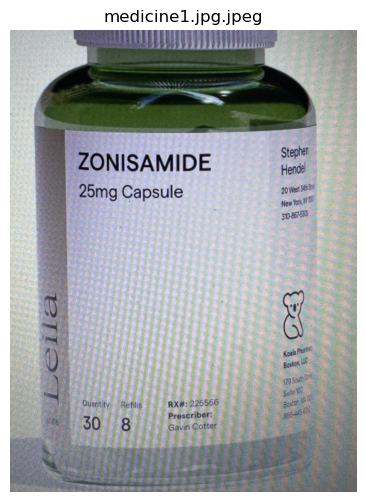

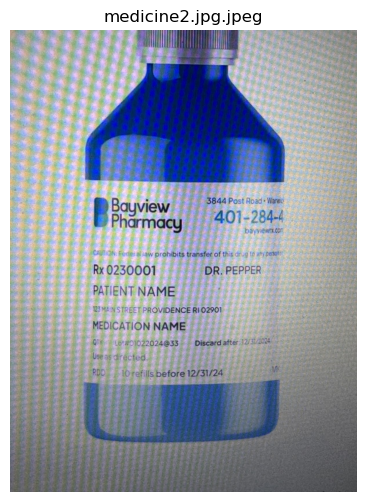

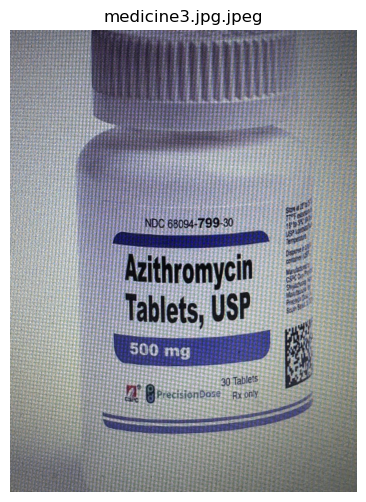

In [2]:
import cv2
import matplotlib.pyplot as plt
import os

MEDICINE_DIR = "medicine_test_images"

medicine_images = [
    f for f in os.listdir(MEDICINE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

for image_name in medicine_images:

    image_path = os.path.join(MEDICINE_DIR, image_name)

    image = cv2.imread(image_path)

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.title(image_name)
        plt.axis("off")
        plt.show()

    else:
        print("Could not open:", image_name)

In [3]:
import easyocr

reader = easyocr.Reader(['en'], gpu=False)

print("OCR system is ready!")

Using CPU. Note: This module is much faster with a GPU.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

C:\Users\nehma\anaconda3\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


OCR system is ready!


In [4]:
import os
import pandas as pd

MEDICINE_DIR = "medicine_test_images"

results = []

medicine_images = [
    f for f in os.listdir(MEDICINE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

for image_name in medicine_images:

    image_path = os.path.join(MEDICINE_DIR, image_name)

    print("\nReading image:", image_name)

    detected_text = reader.readtext(image_path)

    for item in detected_text:

        text = item[1]
        confidence = item[2]

        print("Detected text:", text)
        print("Confidence:", round(confidence, 2))

        results.append({
            "Image": image_name,
            "Detected Text": text,
            "Confidence": confidence
        })

print("\nMedicine text reading completed!")


Reading image: medicine1.jpg.jpeg


C:\Users\nehma\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Detected text: Stephan 
Confidence: 0.46
Detected text: ZONISAMIDE
Confidence: 0.99
Detected text: Hendyl
Confidence: 0.34
Detected text: Capsule
Confidence: 0.96
Detected text: Kem]
Confidence: 0.28
Detected text: 7
Confidence: 0.25
Detected text: 1
Confidence: 0.71
Detected text: Et W
Confidence: 0.07
Detected text: Jule
Confidence: 0.29
Detected text: NL
Confidence: 0.2
Detected text: Quant ty
Confidence: 0.13
Detected text: Rel
Confidence: 0.96
Detected text: RX#: 225566
Confidence: 0.81
Detected text: Prescriber:
Confidence: 0.95
Detected text: Lt6
Confidence: 0.08
Detected text: 30
Confidence: 1.0
Detected text: 8
Confidence: 1.0
Detected text: Guvin Catter
Confidence: 0.4
Detected text: 25mg
Confidence: 1.0
Detected text: 201e158
Confidence: 0.04
Detected text: ltm
Confidence: 0.06
Detected text: sprtr
Confidence: 0.03
Detected text: Rr
Confidence: 0.08
Detected text: KabF
Confidence: 0.14
Detected text: KT
Confidence: 0.03
Detected text: Hoste
Confidence: 0.03

Reading image: m

C:\Users\nehma\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Detected text: 3844 Past Roade Mia
Confidence: 0.16
Detected text: Bayview
Confidence: 0.99
Detected text: 401-284-4
Confidence: 0.7
Detected text: Pharmacy
Confidence: 1.0
Detected text: djkuetmte
Confidence: 0.03
Detected text: prohlbits transteroity Oilaj A5fzi
Confidence: 0.0
Detected text: Rx 0230001
Confidence: 0.96
Detected text: DR. PEPPER
Confidence: 0.6
Detected text: PATIENT NAME
Confidence: 0.92
Detected text: STQEET PROMIDENCE RI 02901
Confidence: 0.55
Detected text: MEDICATION NAME
Confidence: 1.0
Detected text: ch
Confidence: 0.08
Detected text: Hetz
Confidence: 0.0
Detected text: 022024633
Confidence: 0.45
Detected text: Discard atter 12317124
Confidence: 0.24
Detected text: Utd
Confidence: 0.13
Detected text: dcecteg
Confidence: 0.11
Detected text: RDD"
Confidence: 0.87
Detected text: 10 rerills pefore 12/31/24
Confidence: 0.4

Reading image: medicine3.jpg.jpeg


C:\Users\nehma\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Detected text: NDC 68094-799-30
Confidence: 0.55
Detected text: 1
Confidence: 0.16
Detected text: Azithromycin
Confidence: 0.99
Detected text: USP
Confidence: 1.0
Detected text: 500 mg
Confidence: 0.95
Detected text: 3 Tablers
Confidence: 0.21
Detected text: n @precisionDose
Confidence: 0.34
Detected text: Rz ont
Confidence: 0.19
Detected text: JC
Confidence: 0.04
Detected text: Tablets;
Confidence: 0.97

Medicine text reading completed!


In [5]:
df = pd.DataFrame(results)

df.to_csv("outputs/medicine_results.csv", index=False)

print("Results saved successfully!")

display(df)

Results saved successfully!


,Image,Detected Text,Confidence
0,medicine1.jpg.jpeg,Stephan,0.459617
1,medicine1.jpg.jpeg,ZONISAMIDE,0.986394
2,medicine1.jpg.jpeg,Hendyl,0.335412
3,medicine1.jpg.jpeg,Capsule,0.956867
4,medicine1.jpg.jpeg,Kem],0.280098
5,medicine1.jpg.jpeg,7,0.252489
6,medicine1.jpg.jpeg,1,0.712092
7,medicine1.jpg.jpeg,Et W,0.067047
8,medicine1.jpg.jpeg,Jule,0.294270
9,medicine1.jpg.jpeg,NL,0.204700


In [6]:
import pandas as pd
import os

file_path = "outputs/medicine_results.csv"

if os.path.exists(file_path):
    medicine_df = pd.read_csv(file_path)
    display(medicine_df)
    print("Medicine results saved successfully!")
else:
    print("Medicine results file not found.")

,Image,Detected Text,Confidence
0,medicine1.jpg.jpeg,Stephan,0.459617
1,medicine1.jpg.jpeg,ZONISAMIDE,0.986394
2,medicine1.jpg.jpeg,Hendyl,0.335412
3,medicine1.jpg.jpeg,Capsule,0.956867
4,medicine1.jpg.jpeg,Kem],0.280098
5,medicine1.jpg.jpeg,7,0.252489
6,medicine1.jpg.jpeg,1,0.712092
7,medicine1.jpg.jpeg,Et W,0.067047
8,medicine1.jpg.jpeg,Jule,0.294270
9,medicine1.jpg.jpeg,NL,0.204700


Medicine results saved successfully!


In [7]:
from deepface import DeepFace

print("DeepFace imported successfully!")


26-11-11 21:21:25 - Directory C:\Users\nehma\.deepface has been created
26-11-11 21:21:25 - Directory C:\Users\nehma\.deepface\weights has been created
DeepFace imported successfully!


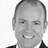

26-11-11 21:21:35 - 🔗 haarcascade_frontalface_default.xml will be downloaded from https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_frontalface_default.xml to C:\Users\nehma\.deepface\weights\haarcascade_frontalface_default.xml...


Downloading...
From: https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_frontalface_default.xml
To: C:\Users\nehma\.deepface\weights\haarcascade_frontalface_default.xml
930kB [00:00, 2.18MB/s]


26-11-11 21:21:46 - 🔗 haarcascade_eye.xml will be downloaded from https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_eye.xml to C:\Users\nehma\.deepface\weights\haarcascade_eye.xml...


Downloading...
From: https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_eye.xml
To: C:\Users\nehma\.deepface\weights\haarcascade_eye.xml
341kB [00:00, 8.47MB/s]


26-11-11 21:21:57 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to C:\Users\nehma\.deepface\weights\facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: C:\Users\nehma\.deepface\weights\facial_expression_model_weights.h5
100%|██████████████████████████████████████████████████████████████████████████████| 5.98M/5.98M [00:22<00:00, 261kB/s]


Dominant Emotion: happy

Emotion Scores:


,angry,disgust,fear,happy,sad,surprise,neutral
0,0.262417,0.000106,2.250475,97.371712,0.051486,0.013253,0.050559


In [8]:
import os
import pandas as pd
from IPython.display import display, Image

emotion_image = os.path.join(
    "emotion_test_images",
    "happy.jpg"
)

display(Image(filename=emotion_image))

result = DeepFace.analyze(
    img_path=emotion_image,
    actions=["emotion"],
    enforce_detection=False
)

if isinstance(result, list):
    result = result[0]

print("Dominant Emotion:", result["dominant_emotion"])

print("\nEmotion Scores:")
display(pd.DataFrame(
    [result["emotion"]]
))

In [9]:
emotion_df = pd.DataFrame([
    {
        "Image": "happy.jpg",
        "Dominant Emotion": result["dominant_emotion"],
        **result["emotion"]
    }
])

emotion_df.to_csv(
    "outputs/emotion_results.csv",
    index=False
)

print("Emotion results saved successfully!")

display(emotion_df)

Emotion results saved successfully!


,Image,Dominant Emotion,angry,disgust,fear,happy,sad,surprise,neutral
0,happy.jpg,happy,0.262417,0.000106,2.250475,97.371712,0.051486,0.013253,0.050559
